<a href="https://colab.research.google.com/github/sivapushadapu/student-stress-detection/blob/main/Student_Stress_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install -q pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

warnings.filterwarnings("ignore")

from google.colab import files

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
import pandas as pd

# Load the dataset from the local path
data = pd.read_csv('/content/Student Stress Factors.csv')

print("Dataset Information:")
data.info()

print("\nFirst 5 Rows:")
display(data.head())

print("\nDataset Description:")
display(data.describe())

print("\nMissing Values:")
print(data.isnull().sum())

print("\nDuplicate Records:", data.duplicated().sum())

print("\nColumn Names:")
print(data.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 7 columns):
 #   Column                                                            Non-Null Count  Dtype 
---  ------                                                            --------------  ----- 
 0   Timestamp                                                         53 non-null     object
 1   Kindly Rate your Sleep Quality 😴                                  53 non-null     int64 
 2   How many times a week do you suffer headaches 🤕?                  53 non-null     int64 
 3   How would you rate you academic performance 👩‍🎓?                  53 non-null     int64 
 4   how would you rate your study load?                               53 non-null     int64 
 5   How many times a week you practice extracurricular activities 🎾?  53 non-null     int64 
 6   How would you rate your stress levels?                            53 non-null     int64 
dtypes: int64(6), object(1)
mem

,Timestamp,Kindly Rate your Sleep Quality 😴,How many times a week do you suffer headaches 🤕?,How would you rate you academic performance 👩‍🎓?,how would you rate your study load?,How many times a week you practice extracurricular activities 🎾?,How would you rate your stress levels?
0,27/10/2023 21:54:15,3,1,3,4,2,3
1,28/10/2023 12:24:40,4,1,2,3,3,2
2,28/10/2023 12:24:51,2,1,2,1,4,4
3,28/10/2023 12:26:11,3,2,3,2,3,3
4,28/10/2023 12:26:45,2,3,1,5,5,3



Dataset Description:


,Kindly Rate your Sleep Quality 😴,How many times a week do you suffer headaches 🤕?,How would you rate you academic performance 👩‍🎓?,how would you rate your study load?,How many times a week you practice extracurricular activities 🎾?,How would you rate your stress levels?
count,53.000000,53.000000,53.000000,53.000000,53.000000,53.000000
mean,3.150943,1.981132,3.226415,2.811321,2.886792,2.792453
std,1.199298,1.263246,1.154281,1.428509,1.449939,1.377826
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2.000000,1.000000,3.000000,2.000000,2.000000,2.000000
50%,3.000000,1.000000,3.000000,2.000000,3.000000,3.000000
75%,4.000000,3.000000,4.000000,4.000000,4.000000,4.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000



Missing Values:
Timestamp                                                           0
Kindly Rate your Sleep Quality 😴                                    0
How many times a week do you suffer headaches 🤕?                    0
How would you rate you academic performance 👩‍🎓?                    0
how would you rate your study load?                                 0
How many times a week you practice extracurricular activities 🎾?    0
How would you rate your stress levels?                              0
dtype: int64

Duplicate Records: 0

Column Names:
['Timestamp', 'Kindly Rate your Sleep Quality 😴', 'How many times a week do you suffer headaches 🤕?', 'How would you rate you academic performance 👩\u200d🎓?', 'how would you rate your study load?', 'How many times a week you practice extracurricular activities 🎾?', 'How would you rate your stress levels?']


In [7]:
# Remove duplicate records
data = data.drop_duplicates().copy()

# Remove unnecessary spaces from column names
data.columns = data.columns.str.strip()

# Target column (matching the correct column name from the dataset)
target = "How would you rate your stress levels?"

if target not in data.columns:
    raise ValueError(
        f"Target column '{target}' not found. "
        "Check your dataset column names."
    )

# Remove rows with missing target values
data = data.dropna(subset=[target]).copy()

# Separate input and output
X = data.drop(columns=[target])
y = data[target]

print("Data cleaning completed!")
print("Input Features:", X.shape)
print("Target Shape:", y.shape)

print("\nStress Level Classes:")
print(y.value_counts().sort_index())

Data cleaning completed!
Input Features: (53, 6)
Target Shape: (53,)

Stress Level Classes:
How would you rate your stress levels?
1    12
2    12
3    12
4     9
5     8
Name: count, dtype: int64


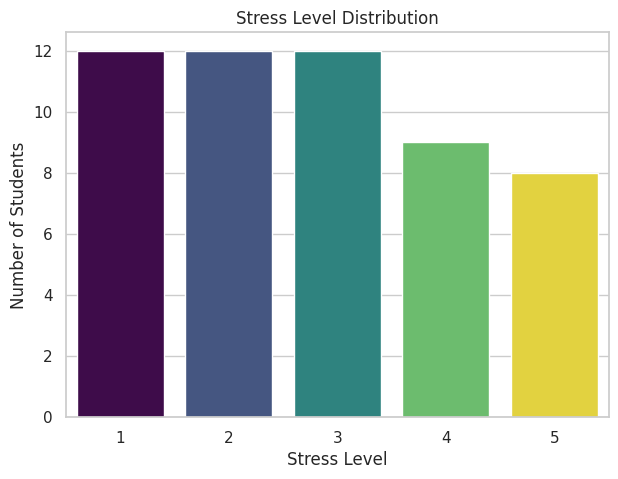

In [8]:

plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    hue=y,
    palette="viridis",
    legend=False
)

plt.title("Stress Level Distribution")
plt.xlabel("Stress Level")
plt.ylabel("Number of Students")
plt.show()


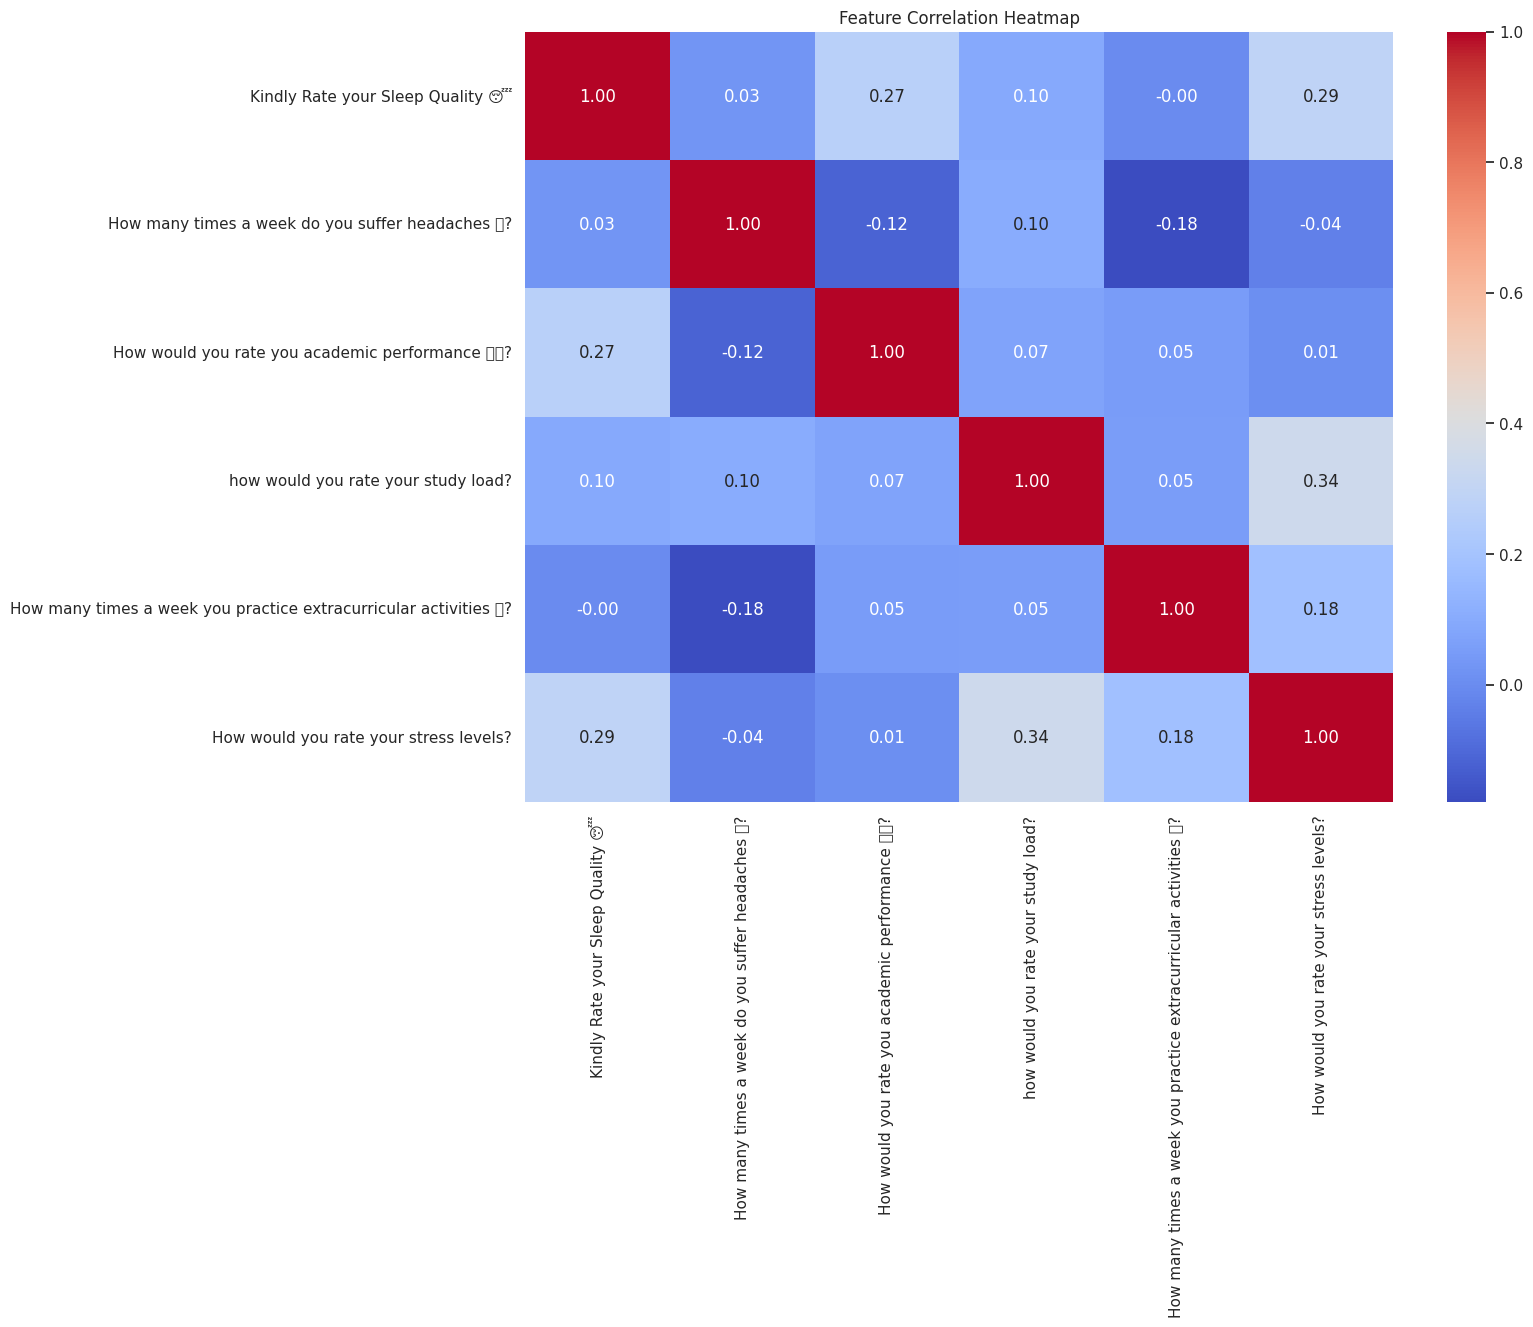

In [9]:

numeric_data = data.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()


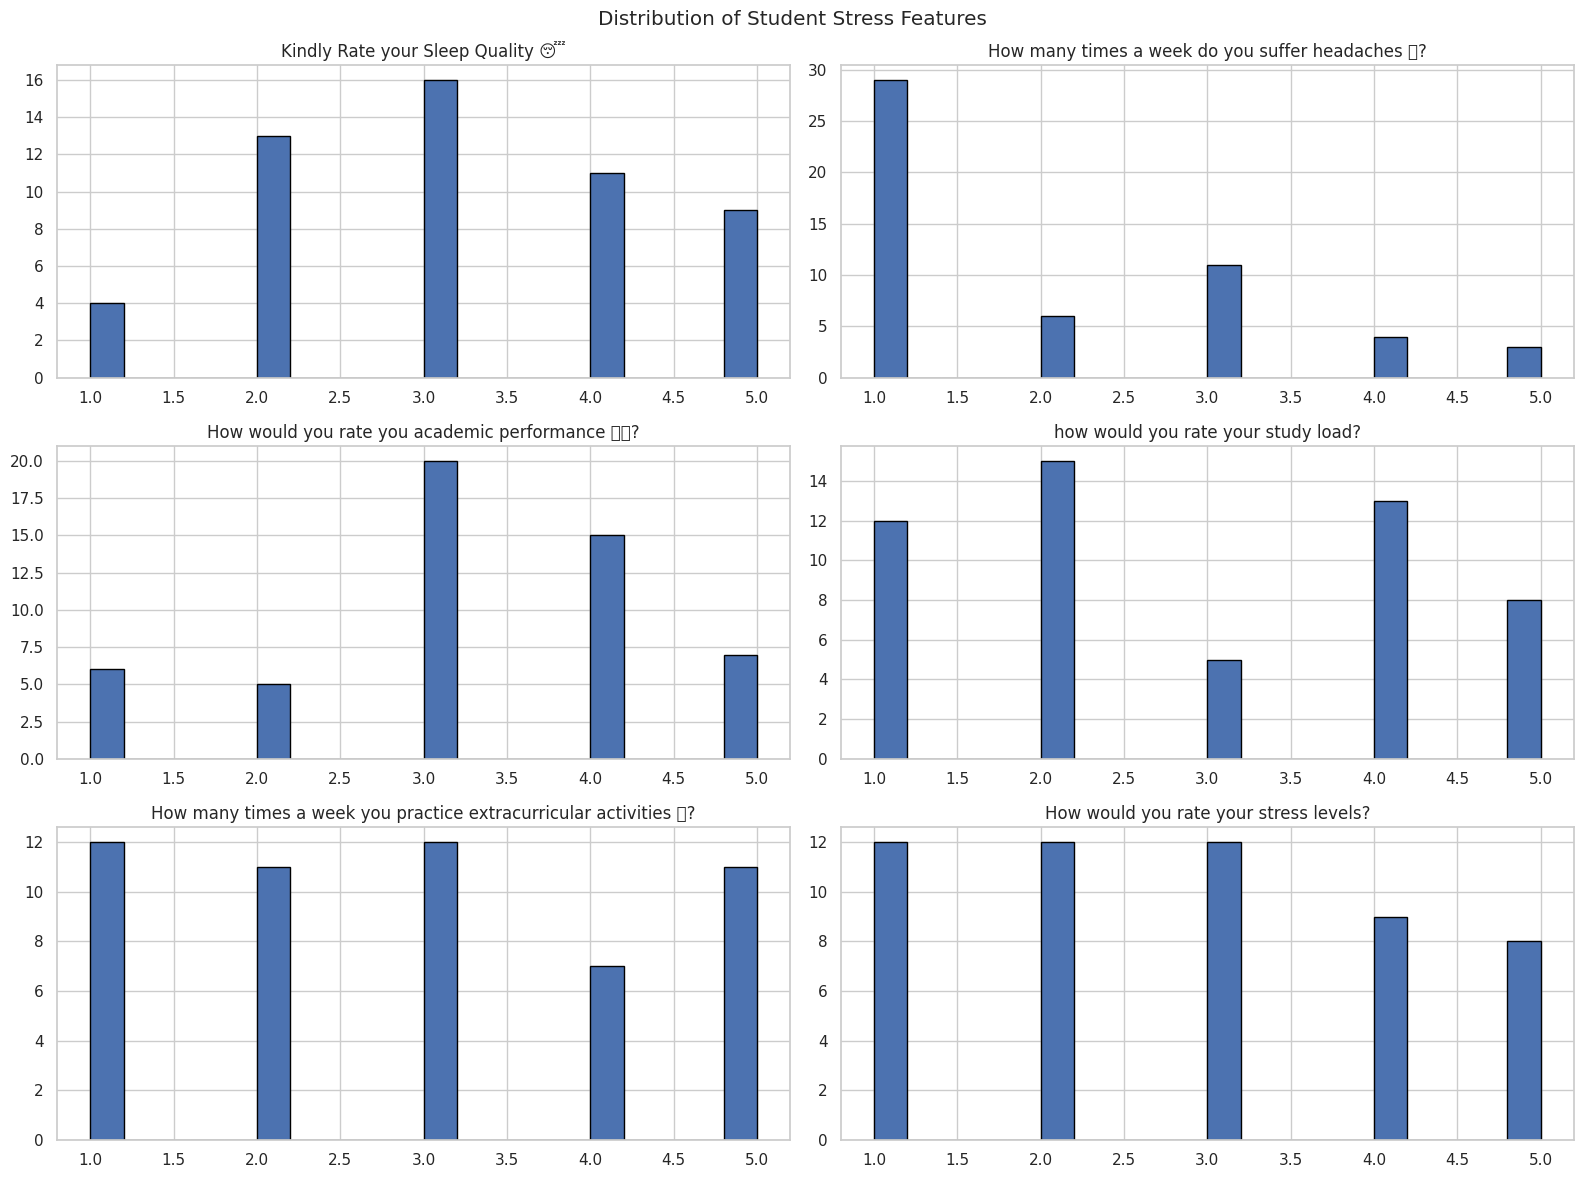

In [10]:

numeric_data.hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Student Stress Features")
plt.tight_layout()
plt.show()


In [11]:

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Preprocessing configuration completed!")


Numerical Features: 5
Categorical Features: 1

Training Data: (42, 6)
Testing Data: (11, 6)
Preprocessing configuration completed!


In [12]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": SVC(
        kernel="rbf"
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    )
}

print("Six ML models defined successfully!")


Six ML models defined successfully!


In [13]:

results = []
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    # Complete pipeline
    clf = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Train model
    clf.fit(X_train, y_train)

    # Prediction
    y_pred = clf.predict(X_test)

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    # Five-fold cross-validation
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    cv_scores = cross_val_score(
        clf,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "CV Accuracy": cv_scores.mean()
    })

    trained_models[name] = clf

    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("Cross Validation:", round(cv_scores.mean(), 4))

print("\nAll models trained successfully!")



Training: Logistic Regression
Accuracy: 27.27 %
Precision: 0.2121
Recall: 0.2727
F1 Score: 0.2273
Cross Validation: 0.1944

Training: Random Forest
Accuracy: 18.18 %
Precision: 0.1818
Recall: 0.1818
F1 Score: 0.1818
Cross Validation: 0.425

Training: SVM
Accuracy: 36.36 %
Precision: 0.2273
Recall: 0.3636
F1 Score: 0.2771
Cross Validation: 0.2139

Training: KNN
Accuracy: 18.18 %
Precision: 0.1152
Recall: 0.1818
F1 Score: 0.1409
Cross Validation: 0.2167

Training: Gradient Boosting
Accuracy: 27.27 %
Precision: 0.2273
Recall: 0.2727
F1 Score: 0.2273
Cross Validation: 0.3083

Training: Decision Tree
Accuracy: 45.45 %
Precision: 0.5
Recall: 0.4545
F1 Score: 0.4545
Cross Validation: 0.3083

All models trained successfully!


In [14]:

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "CV Accuracy": "{:.4f}"
    })
)


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,CV Accuracy
0,Decision Tree,0.4545,0.5000,0.4545,0.4545,0.3083
1,SVM,0.3636,0.2273,0.3636,0.2771,0.2139
2,Gradient Boosting,0.2727,0.2273,0.2727,0.2273,0.3083
3,Logistic Regression,0.2727,0.2121,0.2727,0.2273,0.1944
4,Random Forest,0.1818,0.1818,0.1818,0.1818,0.4250
5,KNN,0.1818,0.1152,0.1818,0.1409,0.2167


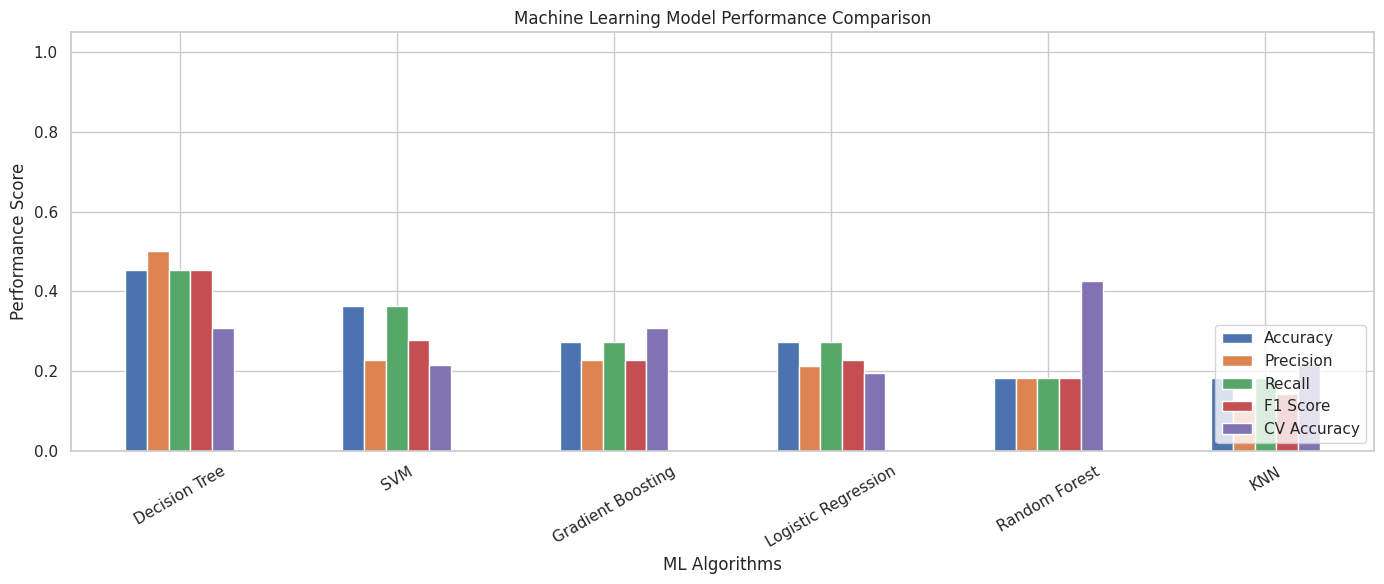

In [15]:

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "CV Accuracy"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Performance Score")
plt.xlabel("ML Algorithms")
plt.xticks(rotation=30)
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [16]:

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

best_predictions = best_model.predict(X_test)

print("\nBest Model Accuracy:",
      round(
          accuracy_score(y_test, best_predictions) * 100,
          2
      ), "%")


Best Model: Decision Tree

Best Model Accuracy: 45.45 %


In [17]:

print("Classification Report")

print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)


Classification Report
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         2
           2       1.00      0.50      0.67         2
           3       0.67      0.67      0.67         3
           4       0.50      0.50      0.50         2
           5       0.25      0.50      0.33         2

    accuracy                           0.45        11
   macro avg       0.48      0.43      0.43        11
weighted avg       0.50      0.45      0.45        11



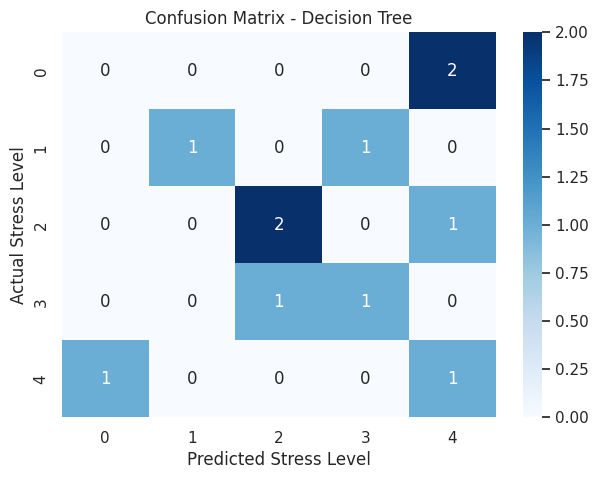

In [18]:

cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - " + best_model_name)
plt.xlabel("Predicted Stress Level")
plt.ylabel("Actual Stress Level")

plt.show()


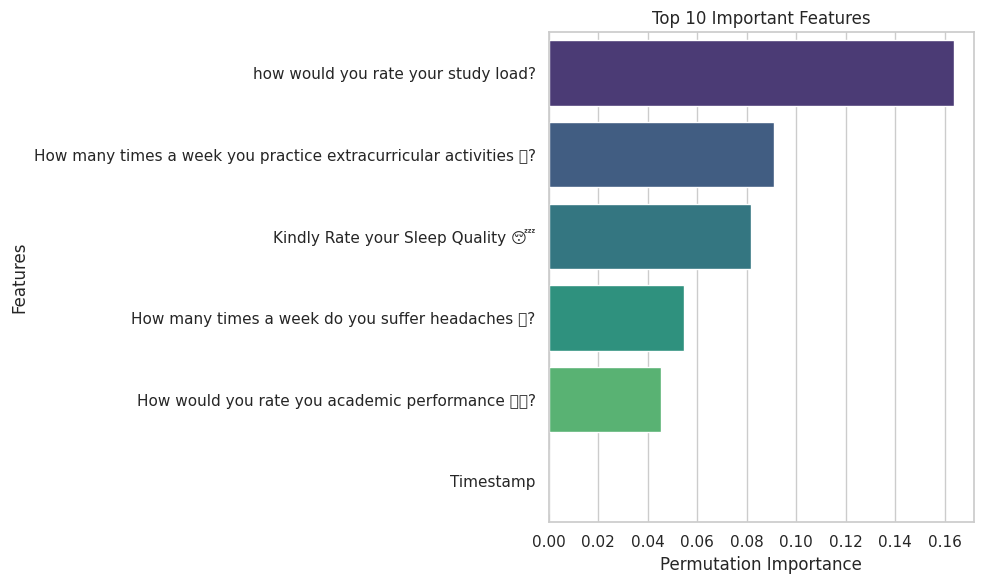

,Feature,Importance
4,how would you rate your study load?,0.163636
5,How many times a week you practice extracurric...,0.090909
1,Kindly Rate your Sleep Quality 😴,0.081818
2,How many times a week do you suffer headaches 🤕?,0.054545
3,How would you rate you academic performance 👩‍🎓?,0.045455
0,Timestamp,0.000000


In [19]:

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="accuracy"
)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance.importances_mean
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Important Features")
plt.xlabel("Permutation Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

display(importance_df)


In [20]:

# Take one student record from the test dataset
sample_student = X_test.iloc[[0]].copy()

prediction = best_model.predict(sample_student)

print("STUDENT STRESS PREDICTION")

print("\nPredicted Stress Level:", prediction[0])

stress_labels = {
    0: "Low Stress",
    1: "Moderate Stress",
    2: "High Stress"
}

print(
    "Stress Category:",
    stress_labels.get(prediction[0], str(prediction[0]))
)

print("\nStudent Input:")
display(sample_student)


STUDENT STRESS PREDICTION

Predicted Stress Level: 5
Stress Category: 5

Student Input:


,Timestamp,Kindly Rate your Sleep Quality 😴,How many times a week do you suffer headaches 🤕?,How would you rate you academic performance 👩‍🎓?,how would you rate your study load?,How many times a week you practice extracurricular activities 🎾?
49,29/10/2023 00:32:26,1,1,1,2,3


In [21]:

print("Enter Student Details")

student_data = {}

for col in X.columns:

    if pd.api.types.is_numeric_dtype(X[col]):
        value = float(input(f"Enter {col}: "))
    else:
        value = input(f"Enter {col}: ")

    student_data[col] = value

new_student = pd.DataFrame(
    [student_data],
    columns=X.columns
)

prediction = best_model.predict(new_student)[0]

print("\n========== RESULT ==========")

print("Predicted Stress Level:", prediction)

print(
    "Stress Category:",
    stress_labels.get(prediction, str(prediction))
)

if hasattr(best_model, "predict_proba"):
    probabilities = best_model.predict_proba(new_student)[0]

    print("\nPrediction Probabilities:")

    for label, probability in zip(
        best_model.classes_,
        probabilities
    ):
        print(
            stress_labels.get(label, str(label)),
            ":",
            round(probability * 100, 2),
            "%"
        )


Enter Student Details
Enter Timestamp: 27/10/2023 21:54:15
Enter Kindly Rate your Sleep Quality 😴: 3
Enter How many times a week do you suffer headaches 🤕?: 1
Enter How would you rate you academic performance 👩‍🎓?: 3
Enter how would you rate your study load?: 4
Enter How many times a week you practice extracurricular activities 🎾?: 2

========== RESULT ==========
Predicted Stress Level: 3
Stress Category: 3

Prediction Probabilities:
Moderate Stress : 0.0 %
High Stress : 0.0 %
3 : 100.0 %
4 : 0.0 %
5 : 0.0 %


In [22]:

# Save best model
joblib.dump(
    best_model,
    "student_stress_model.pkl"
)

# Save comparison results
results_df.to_csv(
    "model_performance.csv",
    index=False
)

print("Model saved successfully!")
print("Performance results saved successfully!")

# Download model
files.download("student_stress_model.pkl")

# Download results
files.download("model_performance.csv")


Model saved successfully!
Performance results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:

loaded_model = joblib.load(
    "student_stress_model.pkl"
)

print("Saved model loaded successfully!")

test_prediction = loaded_model.predict(X_test.iloc[[0]])

print("Prediction:", test_prediction[0])

print(
    "Category:",
    stress_labels.get(
        test_prediction[0],
        str(test_prediction[0])
    )
)


Saved model loaded successfully!
Prediction: 5
Category: 5
